In [2]:
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
def get_total_size_mb(folder_path):
    total_size = 0
    for root, dirs, files in os.walk(folder_path):
        for file in files:
            if file.lower().endswith(('.m4s', '.webm')):
                file_path = os.path.join(root, file)
                total_size += os.path.getsize(file_path)
    return total_size / (1024 * 1024)  # bytes -> MB

folder = "../crf/output/e0h0_cat00/FULL_av1/"
print(f"Total size: {get_total_size_mb(folder):.2f} MB")

Total size: 133.50 MB


## Creating encoding metrics dataframe

In [4]:
vids = os.listdir("../crf/output/")
encoding_settings = os.listdir("../crf/output/e0h0_cat00/")

print(f"Video IDS:\n\t{vids}")
print(f"Encoding Settings:\n\t{encoding_settings}")

Video IDS:
	['e2h3_cat14', 'e1h2_cat09', 'e0h0_cat00', 'e2h2_cat10', 'e0h1_cat04', 'e2h0_cat02', 'e1h0_cat01', 'e3h2_cat11', 'e3h1_cat07', 'e1h1_cat05', 'e3h0_cat03', 'e3h3_cat15']
Encoding Settings:
	['HD_vp9', 'SD_av1', 'HD_av1', 'HD_h264', 'FULL_h264', 'SD_vp9', 'QUHD_vp9', 'FULL_vp9', 'QUHD_h264', 'FULL_av1', 'QUHD_av1', 'SD_h264']


In [5]:

encoder_metrics = pd.DataFrame()
for vid in vids:
    for enc in encoding_settings:
        df = pd.read_csv(f"../crf/output/{vid}/{enc}/energy.csv")
        df['total_energy'] = (df['rapl0_delta_uj'] + df['rapl1_delta_uj']) * (1e-9) # Converting microJoules to KiloJoules

        energy = df[10:-10]['total_energy'].sum()
        time = len(df[10:-10])
        power = df['total_energy'][10:-10].mean()

        size = get_total_size_mb(f"../crf/output/{vid}/{enc}")

        encoder_metrics = pd.concat([encoder_metrics,pd.DataFrame({
                    "vid":[vid],
                    "codec":[enc.split("_")[1]],
                    "ladder":[enc.split("_")[0]],
                    "energy_kJ":[energy],
                    "time_sec":[time],
                    "power_kW":[power],
                    "size_MB":[size],
                })])
encoder_metrics = encoder_metrics.reset_index(drop=True)        

In [6]:
encoder_metrics

,vid,codec,ladder,energy_kJ,time_sec,power_kW,size_MB
0,e2h3_cat14,vp9,HD,182.499037,1196,0.152591,68.496077
1,e2h3_cat14,av1,SD,32.788876,137,0.239335,14.531649
2,e2h3_cat14,av1,HD,81.882101,336,0.243697,36.374623
3,e2h3_cat14,h264,HD,31.186624,123,0.253550,138.468518
4,e2h3_cat14,h264,FULL,47.722782,213,0.224051,189.467092
...,...,...,...,...,...,...,...
139,e3h3_cat15,vp9,FULL,566.965002,2321,0.244276,352.363312
140,e3h3_cat15,h264,QUHD,48.338822,221,0.218728,189.503151
141,e3h3_cat15,av1,FULL,351.833338,1204,0.292220,215.881924
142,e3h3_cat15,av1,QUHD,267.635125,966,0.277055,166.190976


<Axes: xlabel='ladder', ylabel='power_kW'>

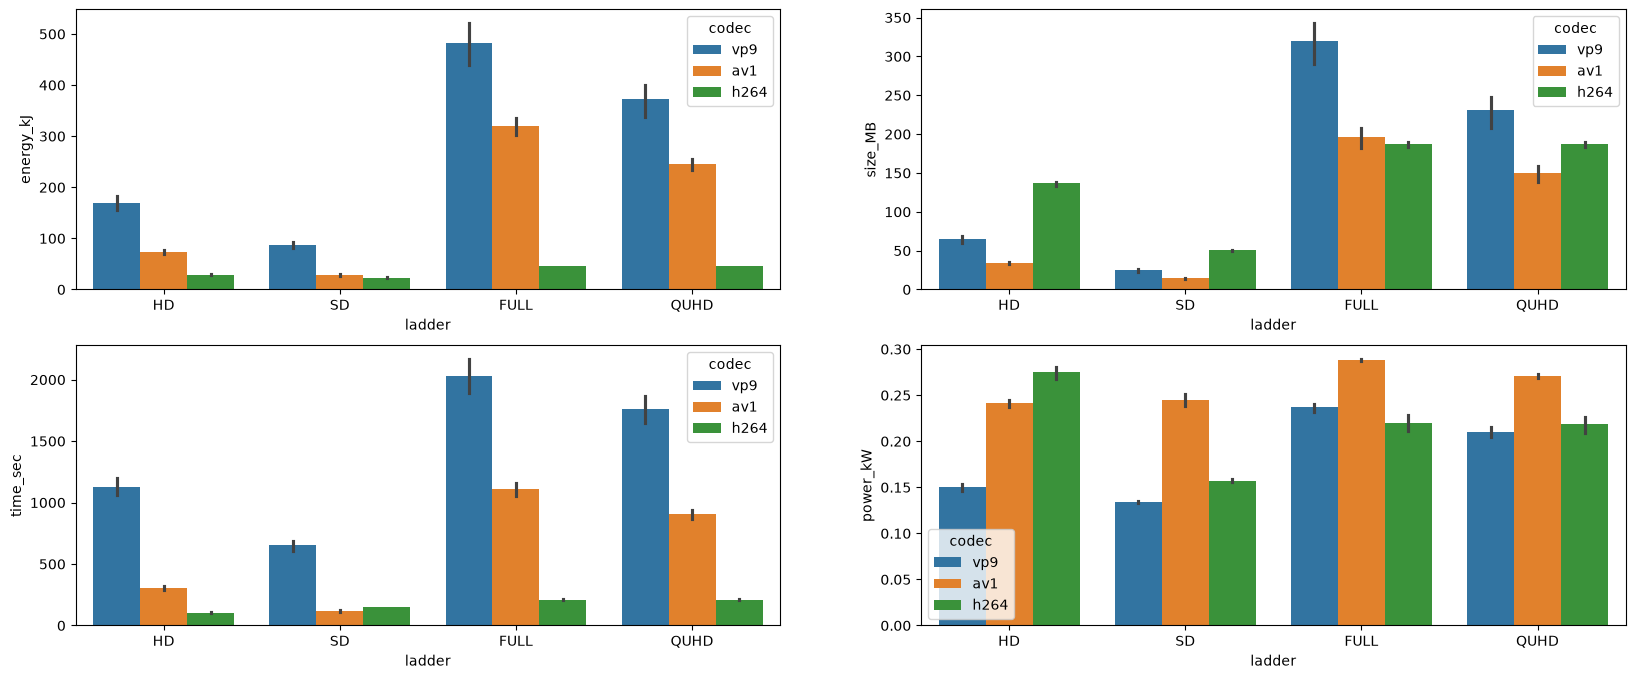

In [7]:
fig,axes = plt.subplots(2,2,figsize=(20,8))
axes = axes.flatten()
sns.barplot(data = encoder_metrics, x='ladder', y='energy_kJ',hue='codec',ax = axes[0])
sns.barplot(data = encoder_metrics, x='ladder', y='size_MB',hue='codec',ax = axes[1])
sns.barplot(data = encoder_metrics, x='ladder', y='time_sec',hue='codec',ax = axes[2])
sns.barplot(data = encoder_metrics, x='ladder', y='power_kW',hue='codec',ax = axes[3])

In [8]:
encoder_metrics.to_csv("./encoding_intel6242_64core_tacc.csv")